## 1. Import libraries and load the dataset

In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---- Settings (increase for higher accuracy) ----
TRAIN_SIZE = 5000    # images used for training (out of 50,000)
TEST_SIZE = 2000     # images used for testing (out of 10,000)
EPOCHS = 3
BATCH_SIZE = 64
LR = 1e-3

Using device: cuda


In [4]:
# CIFAR-10 is downloaded automatically (about 170 MB) and images are resized to 224 x 224
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([transforms.Resize(224), transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
test_tf = transforms.Compose([transforms.Resize(224), transforms.ToTensor(), norm])

full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_tf)
full_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_tf)

# Random subsets keep training fast
g = torch.Generator().manual_seed(SEED)
train_idx = torch.randperm(len(full_train), generator=g)[:TRAIN_SIZE].tolist()
test_idx = torch.randperm(len(full_test), generator=g)[:TEST_SIZE.].tolist()
train_ds, test_ds = Subset(full_train, train_idx), Subset(full_test, test_idx)

train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

classes = full_train.classes
print("Classes:", classes)
print(f"Full dataset: {len(full_train)} train / {len(full_test)} test images (32 x 32 RGB)")
print(f"Used here   : {len(train_ds)} train / {len(test_ds)} test images (resized to 224 x 224)")

100%|██████████| 170M/170M [27:30<00:00, 103kB/s] 


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Full dataset: 50000 train / 10000 test images (32 x 32 RGB)
Used here   : 5000 train / 2000 test images (resized to 224 x 224)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Full dataset: 50000 train / 10000 test images (32 x 32 RGB)
Used here   : 5000 train / 2000 test images (resized to 224 x 224)


## 2. Visualize the data

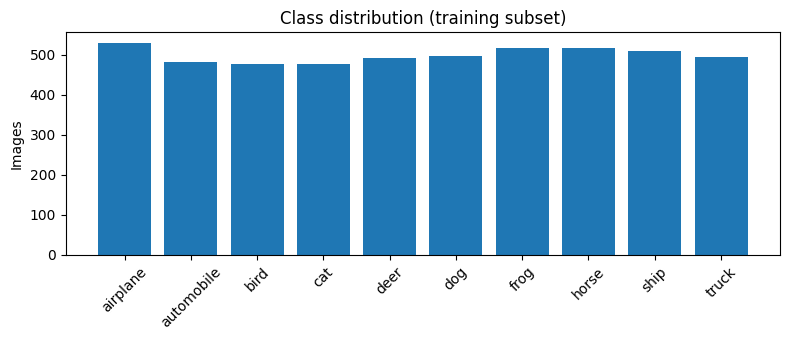

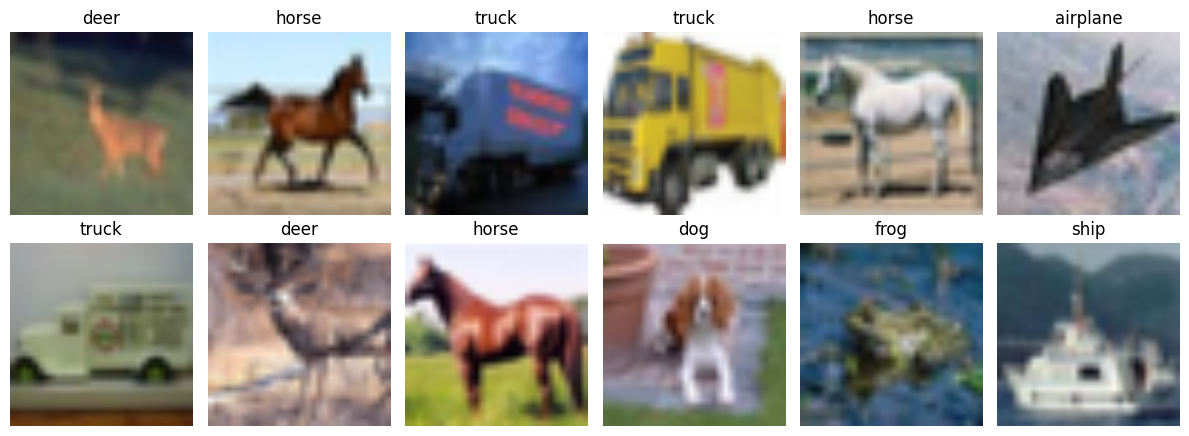

In [5]:
inv_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
inv_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def show_img(t):
    return (t.cpu() * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0).numpy()

# class distribution of the training subset
labels = [full_train.targets[i] for i in train_idx]
counts = np.bincount(labels, minlength=10)
plt.figure(figsize=(8, 3.5))
plt.bar(classes, counts, color="tab:blue")
plt.title("Class distribution (training subset)")
plt.xticks(rotation=45); plt.ylabel("Images")
plt.tight_layout(); plt.show()

# sample images
x, y = next(iter(train_dl))
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, lab in zip(axes.flat, x, y):
    ax.imshow(show_img(img)); ax.set_title(classes[lab]); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Load the pre-trained ViT and CNN models

In [6]:
def build_model(name):
    if name == "ViT-B/16":
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        m.heads.head = nn.Linear(768, 10)          # new classification head
    elif name == "ResNet50 (CNN)":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        for p in m.parameters(): p.requires_grad = False
        m.fc = nn.Linear(2048, 10)                 # new classification head
    return m.to(device)

for n in ["ViT-B/16", "ResNet50 (CNN)"]:
    m = build_model(n)
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{n:16s} total params: {total:,} | trainable params: {trainable:,}")
    del m

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 177MB/s]


ViT-B/16         total params: 85,806,346 | trainable params: 7,690
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]


ResNet50 (CNN)   total params: 23,528,522 | trainable params: 20,490


## 4. Train both models (transfer learning: only the new head is trained)

In [7]:
use_cuda = device.type == "cuda"

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    if train:  # keep frozen BatchNorm layers (ResNet) in eval mode
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_cuda):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def train_model(name):
    model = build_model(name)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    start = time.time()
    for ep in range(EPOCHS):
        tl, ta = run_epoch(model, train_dl, criterion, optimizer, scaler)
        vl, va = run_epoch(model, test_dl, criterion)
        for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
        print(f"{name} | epoch {ep+1}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | test loss {vl:.4f} acc {va:.4f}")
    hist["train_time"] = time.time() - start
    return model, hist

In [8]:
models_trained, history = {}, {}
for name in ["ViT-B/16", "ResNet50 (CNN)"]:
    print(f"\n===== {name} =====")
    models_trained[name], history[name] = train_model(name)
    torch.cuda.empty_cache()


===== ViT-B/16 =====
ViT-B/16 | epoch 1/3 | train loss 0.6475 acc 0.8546 | test loss 0.2628 acc 0.9320
ViT-B/16 | epoch 2/3 | train loss 0.2125 acc 0.9428 | test loss 0.2121 acc 0.9370
ViT-B/16 | epoch 3/3 | train loss 0.1673 acc 0.9536 | test loss 0.1922 acc 0.9400

===== ResNet50 (CNN) =====
ResNet50 (CNN) | epoch 1/3 | train loss 1.1233 acc 0.7472 | test loss 0.6267 acc 0.8490
ResNet50 (CNN) | epoch 2/3 | train loss 0.5050 acc 0.8734 | test loss 0.4533 acc 0.8705
ResNet50 (CNN) | epoch 3/3 | train loss 0.3759 acc 0.9020 | test loss 0.3912 acc 0.8860


## 5. Evaluate both models

In [9]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, elapsed = [], [], 0.0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        if use_cuda: torch.cuda.synchronize()
        start = time.time()                      # time only the model's forward pass
        with torch.autocast(device_type=device.type, enabled=use_cuda):
            out = model(x)
        if use_cuda: torch.cuda.synchronize()
        elapsed += time.time() - start
        ps.append(out.argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), elapsed

preds = {}
for name, model in models_trained.items():
    y_true, y_pred, t = predict(model, test_dl)
    preds[name] = (y_true, y_pred, t)
    print(f"\n===== {name} =====")
    print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(classification_report(y_true, y_pred, target_names=classes, digits=3))


===== ViT-B/16 =====
Test accuracy: 0.9400
              precision    recall  f1-score   support

    airplane      0.951     0.964     0.957       221
  automobile      0.977     0.968     0.973       222
        bird      0.938     0.938     0.938       195
         cat      0.903     0.903     0.903       206
        deer      0.895     0.885     0.890       192
         dog      0.920     0.911     0.915       190
        frog      0.945     0.974     0.960       195
       horse      0.945     0.905     0.925       210
        ship      0.969     0.979     0.974       189
       truck      0.951     0.972     0.962       180

    accuracy                          0.940      2000
   macro avg      0.939     0.940     0.940      2000
weighted avg      0.940     0.940     0.940      2000


===== ResNet50 (CNN) =====
Test accuracy: 0.8860
              precision    recall  f1-score   support

    airplane      0.897     0.910     0.903       221
  automobile      0.972     0.928     

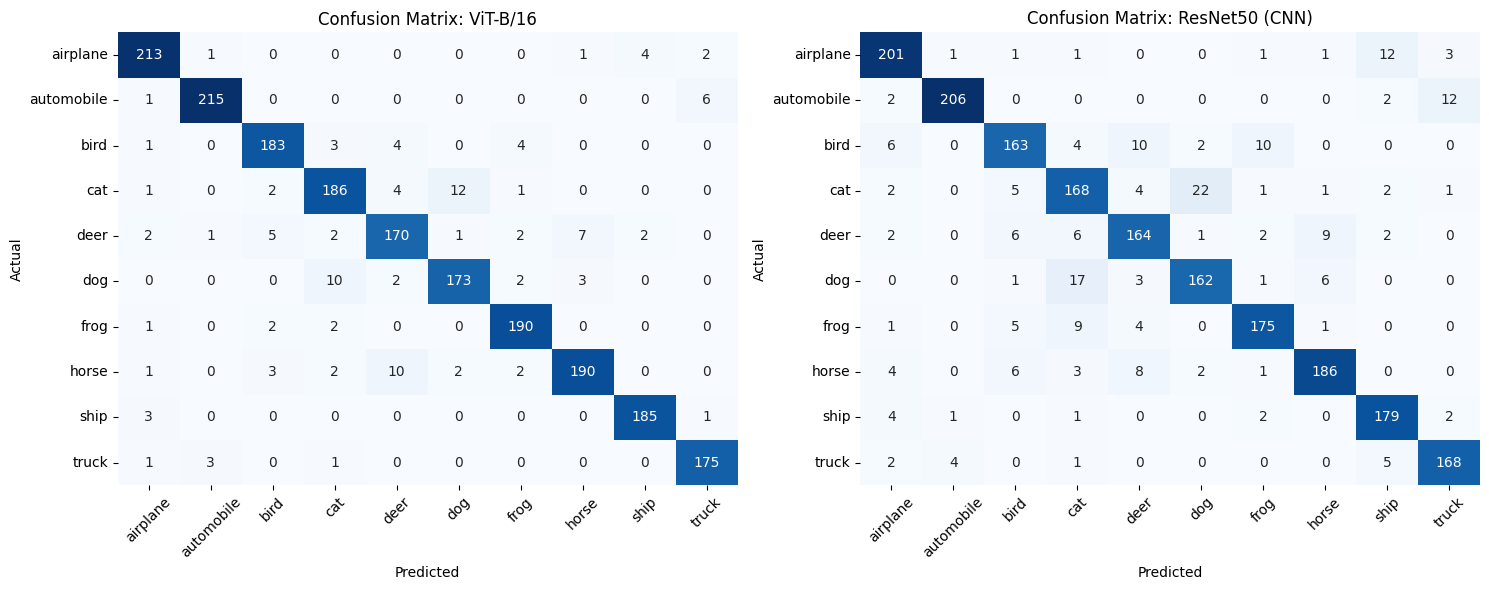

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, (y_true, y_pred, _)) in zip(axes, preds.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 6. Compare ViT and CNN

In [11]:
rows = {}
for name in models_trained:
    y_true, y_pred, t = preds[name]
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    m = models_trained[name]
    rows[name] = {
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Test Loss": history[name]["test_loss"][-1],
        "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
        "Training Time (s)": history[name]["train_time"],
        "Inference Time (ms/image)": 1000 * t / len(y_true),
        "Total Params (M)": sum(q.numel() for q in m.parameters()) / 1e6,
        "Trainable Params": sum(q.numel() for q in m.parameters() if q.requires_grad),
    }
comparison = pd.DataFrame(rows).T
comparison.round(4)

,Test Accuracy,Test Loss,Precision (macro),Recall (macro),F1 (macro),Training Time (s),Inference Time (ms/image),Total Params (M),Trainable Params
ViT-B/16,0.940,0.1922,0.9395,0.9400,0.9396,65.2555,3.0306,85.8063,7690.0
ResNet50 (CNN),0.886,0.3912,0.8855,0.8859,0.8855,39.2381,1.1874,23.5285,20490.0


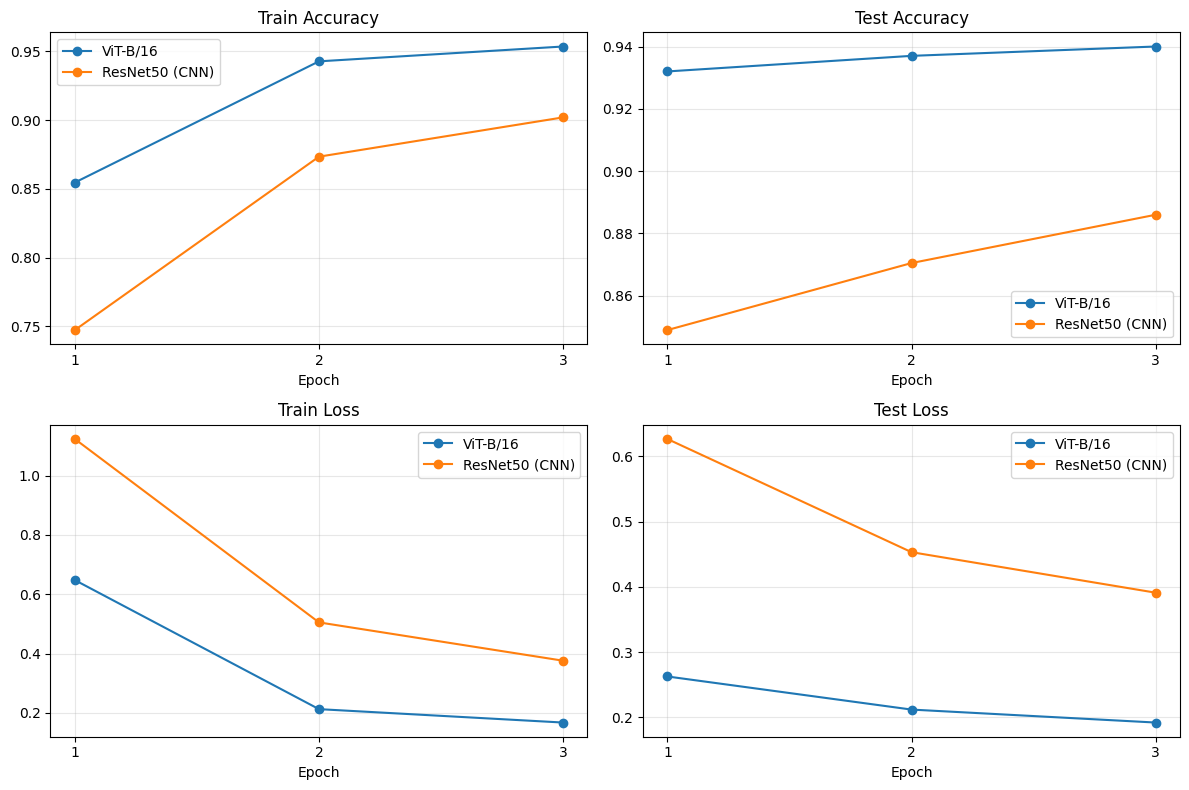

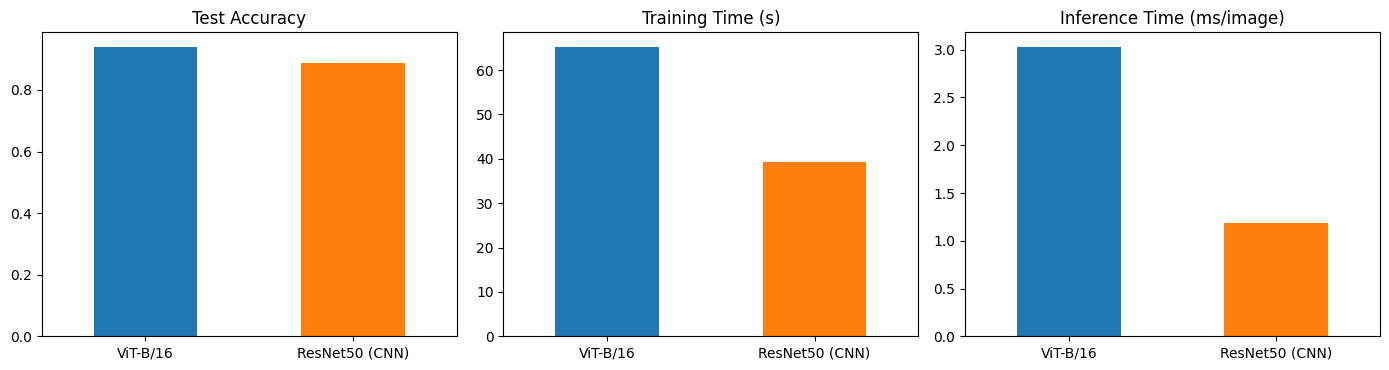

In [12]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for name, h in history.items():
    ax[0, 0].plot(ep, h["train_acc"], marker="o", label=name)
    ax[0, 1].plot(ep, h["test_acc"], marker="o", label=name)
    ax[1, 0].plot(ep, h["train_loss"], marker="o", label=name)
    ax[1, 1].plot(ep, h["test_loss"], marker="o", label=name)
for a, t in zip(ax.flat, ["Train Accuracy", "Test Accuracy", "Train Loss", "Test Loss"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
    a.set_xticks(list(ep))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
comparison["Test Accuracy"].plot.bar(ax=ax[0], color=["tab:blue", "tab:orange"], title="Test Accuracy", rot=0)
comparison["Training Time (s)"].plot.bar(ax=ax[1], color=["tab:blue", "tab:orange"], title="Training Time (s)", rot=0)
comparison["Inference Time (ms/image)"].plot.bar(ax=ax[2], color=["tab:blue", "tab:orange"], title="Inference Time (ms/image)", rot=0)
plt.tight_layout(); plt.show()

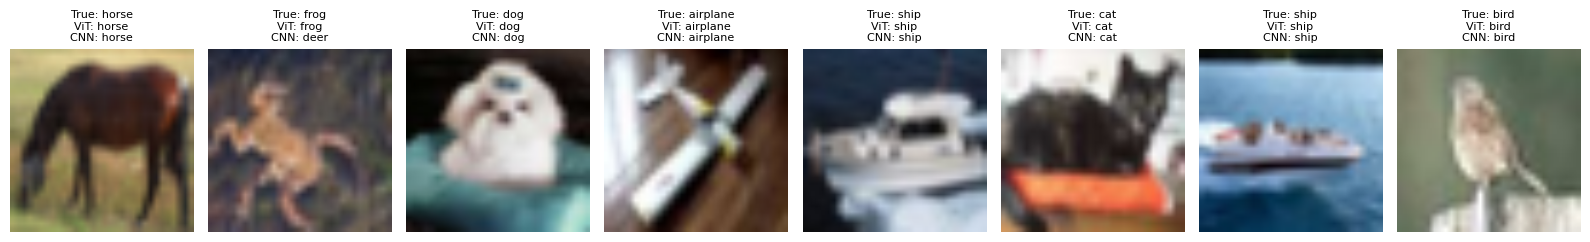

In [13]:
# Sample predictions of both models on the same test images
x, y = next(iter(test_dl))
x_gpu = x[:8].to(device)
out = {}
for name, model in models_trained.items():
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=use_cuda):
        out[name] = model(x_gpu).argmax(1).cpu()

fig, axes = plt.subplots(1, 8, figsize=(16, 3.2))
for i, ax in enumerate(axes):
    ax.imshow(show_img(x[i])); ax.axis("off")
    ax.set_title(f"True: {classes[y[i]]}\nViT: {classes[out['ViT-B/16'][i]]}\nCNN: {classes[out['ResNet50 (CNN)'][i]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
best = comparison["Test Accuracy"].idxmax()
print(f"Best model by test accuracy: {best} ({comparison.loc[best, 'Test Accuracy']:.4f})")
faster = comparison["Inference Time (ms/image)"].idxmin()
print(f"Fastest at inference: {faster} ({comparison.loc[faster, 'Inference Time (ms/image)']:.2f} ms/image)")

Best model by test accuracy: ViT-B/16 (0.9400)
Fastest at inference: ResNet50 (CNN) (1.19 ms/image)
